# 01 · Auditoría de cobertura PROFECO – ENSU

Antes de cualquier gráfica, se decide qué municipios PROFECO pueden compararse con
un área urbana de la ENSU. Se revisan ambas fuentes por separado y luego se construye
`homologacion_geografica.csv`.

**Regla:** no se une por parecido de nombres de ciudad. Cada municipio PROFECO se
lleva a su clave INEGI y se busca en la composición municipal oficial de cada área
ENSU, obtenida de los microdatos del mismo levantamiento.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
PROC = ROOT / "data/processed"
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
from src.ensu import load_ensu, manifest, download, PERIODO
from src.geographic_matching import (ensu_composition, attach_area_names, match, classify,
                                     UMBRAL_DIRECTA, UMBRAL_APROXIMADA)
download()  # solo descarga si faltan los paquetes oficiales
profeco_mun = pd.read_csv(PROC / "cobertura_municipios_profeco.csv")
print(f"PROFECO: {len(profeco_mun)} parejas estado–municipio")

PROFECO: 72 parejas estado–municipio


## 1. PROFECO (resumen de la fase 1)

Se reutiliza la tabla de cobertura exportada en `00_exploracion_profeco.ipynb`.

In [2]:
display(profeco_mun[["registros", "establecimientos", "productos", "dias_observados"]].describe().round(1))
display(profeco_mun[["estado", "municipio", "registros", "establecimientos", "fecha_inicio", "fecha_fin"]]
        .sort_values("registros").head(10))

,registros,establecimientos,productos,dias_observados
count,72.0,72.0,72.0,72.0
mean,9133.4,25.8,557.3,6.7
std,7020.8,19.6,221.0,3.9
min,2.0,1.0,1.0,1.0
25%,3391.0,6.8,523.2,3.0
50%,8988.5,25.0,661.0,6.0
75%,13742.0,41.2,699.2,11.0
max,31512.0,82.0,730.0,12.0


,estado,municipio,registros,establecimientos,fecha_inicio,fecha_fin
71,Nuevo León,General Escobedo,2,1,2026-08-17,2026-08-24
70,Estado de México,Atizapán,2,1,2026-08-17,2026-08-24
69,Estado de México,Tecámac,3,3,2026-08-28,2026-08-28
68,Estado de México,Chicoloapan,3,3,2026-08-28,2026-08-28
67,Oaxaca,Santa Lucia del Camino,10,5,2026-08-19,2026-08-27
66,Tamaulipas,Ciudad Madero,25,5,2026-08-18,2026-08-28
65,Hidalgo,Pachuca de Soto,232,1,2026-08-18,2026-08-18
64,Jalisco,Tlaquepaque,357,3,2026-08-17,2026-08-31
63,Nuevo León,Guadalupe,672,14,2026-08-17,2026-08-31
62,Ciudad de México,Magdalena Contreras,1129,3,2026-08-28,2026-08-28


## 2. ENSU

- **Periodo:** junio 2026, la publicación más reciente en el sitio de INEGI al 19-oct-2026
  (levantamiento del 22 de mayo al 12 de junio de 2026, según el comunicado de INEGI).
  La de septiembre 2026 aún no está publicada.
- **Indicador:** cuadro 1.7 de los tabulados básicos, «Población de 18 años y más por área
  urbana y características de percepción de seguridad pública». Se usa el porcentaje
  **«seguro»** que publica INEGI. No se calcula `100 − inseguro` porque la diferencia es
  «no sabe / no responde».
- Se conservan coeficiente de variación e intervalo de confianza al 90 % de los tabulados oficiales.

In [3]:
ensu = load_ensu()
areas = ensu[ensu.estado_ensu.ne("Nacional")]
print(f"Áreas urbanas en el cuadro: {areas.area_urbana_ensu.nunique()} · entidades: {areas.estado_ensu.nunique()}")
print("Nacional (seguro / inseguro):", ensu.loc[ensu.estado_ensu.eq('Nacional'), ['seguridad_pct', 'inseguridad_pct']].round(1).values.tolist())
dup = areas[areas.duplicated("area_urbana_ensu", keep=False)]
display(Markdown("Áreas que aparecen en dos entidades (interestatales):"))
display(dup[["estado_ensu", "area_urbana_ensu", "seguridad_pct"]])
areas = areas.drop_duplicates("area_urbana_ensu")
areas["precision"] = pd.cut(areas.cv_pct_seguro, [0, 15, 30, np.inf], right=False,
                            labels=["alta", "moderada", "baja"])
display(areas.precision.value_counts())
display(areas.sort_values("seguridad_pct")[["estado_ensu", "area_urbana_ensu", "seguridad_pct",
        "inseguridad_pct", "no_responde_pct", "cv_pct_seguro", "ic90_inf_seguro", "ic90_sup_seguro"]].round(1))

Áreas urbanas en el cuadro: 91 · entidades: 32
Nacional (seguro / inseguro): [[40.0, 59.8]]


Áreas que aparecen en dos entidades (interestatales):

,estado_ensu,area_urbana_ensu,seguridad_pct
27,Coahuila de Zaragoza,La Laguna2,71.787443
34,Durango,La Laguna2,71.787443


precision
alta        85
moderada     6
baja         0
Name: count, dtype: int64

,estado_ensu,area_urbana_ensu,seguridad_pct,inseguridad_pct,no_responde_pct,cv_pct_seguro,ic90_inf_seguro,ic90_sup_seguro
36,Guanajuato,Irapuato,8.4,91.2,0.3,21.9,5.4,11.4
75,Sinaloa,Culiacán Rosales,9.2,90.8,0.0,24.6,5.5,13.0
84,Tamaulipas,Reynosa,13.4,86.6,0.0,17.8,9.5,17.3
81,Tabasco,Villahermosa,15.8,84.2,0.0,14.1,12.1,19.5
50,Michoacán de Ocampo,Uruapan,16.9,83.1,0.0,15.4,12.6,21.2
...,...,...,...,...,...,...,...,...
23,Ciudad de México,Benito Juárez,82.3,17.4,0.4,3.7,77.2,87.3
66,Nuevo León,San Nicolás de los Garza,83.0,16.9,0.1,3.4,78.4,87.6
29,Coahuila de Zaragoza,Saltillo,83.1,16.9,-0.0,3.8,77.9,88.3
28,Coahuila de Zaragoza,Piedras Negras,86.1,13.9,0.0,2.6,82.4,89.8


In [4]:
# Control: seguro + inseguro + no responde = 100 y los intervalos contienen la estimación.
assert np.allclose(areas.seguridad_pct + areas.inseguridad_pct + areas.no_responde_pct, 100)
assert (areas.ic90_inf_seguro <= areas.seguridad_pct).all() and (areas.seguridad_pct <= areas.ic90_sup_seguro).all()
assert areas.no_responde_pct.between(-0.01, 3).all()
print("Controles ENSU correctos.")

Controles ENSU correctos.


## 3. Composición municipal de las áreas ENSU

Los microdatos (`ENSU_CB_0626.csv`) contienen para cada persona entrevistada el área
(`CD`) y su municipio (`CVE_ENT`, `CVE_MUN`). Sumando el factor de expansión `FAC_SEL`
se estima qué parte de la población de 18+ de cada área vive en cada municipio.
Las notas del tabulado lo confirman para La Laguna, Los Cabos y Zacatecas. El catálogo
oficial de ciudades ENSU 2025 (PDF en `data/raw/ensu/`) se contrastó con estas claves:
coinciden salvo seis municipios periféricos pequeños, por cambios de muestra entre periodos.

In [5]:
comp = attach_area_names(ensu_composition(), ensu)
multi = comp.groupby("area_urbana_ensu").filter(lambda g: len(g) > 1)
print(f"{comp.CD.nunique()} áreas en microdatos; {multi.area_urbana_ensu.nunique()} incluyen más de un municipio")
display(multi.sort_values(["area_urbana_ensu", "participacion_area_pct"], ascending=[True, False])
        [["area_urbana_ensu", "NOM_ENT", "NOM_MUN", "personas_muestra", "participacion_area_pct"]].round(1).head(40))

90 áreas en microdatos; 24 incluyen más de un municipio


,area_urbana_ensu,NOM_ENT,NOM_MUN,personas_muestra,participacion_area_pct
0,Aguascalientes,AGUASCALIENTES,AGUASCALIENTES,240,89.5
1,Aguascalientes,AGUASCALIENTES,JESUS MARIA,26,10.5
114,Coatzacoalcos,VERACRUZ DE IGNACIO DE LA LLAVE,COATZACOALCOS,249,97.5
115,Coatzacoalcos,VERACRUZ DE IGNACIO DE LA LLAVE,COSOLEACAQUE,8,2.5
15,Colima,COLIMA,VILLA DE ALVAREZ,165,60.9
14,Colima,COLIMA,COLIMA,108,39.1
44,Cuernavaca,MORELOS,CUERNAVACA,136,49.2
46,Cuernavaca,MORELOS,JIUTEPEC,59,21.3
45,Cuernavaca,MORELOS,EMILIANO ZAPATA,26,13.3
47,Cuernavaca,MORELOS,TEMIXCO,29,8.8


## 4. Homologación

Para cada área se suma la participación de los municipios que PROFECO observa.

| Tipo | Regla |
|---|---|
| directa | Los municipios PROFECO cubren ≥ 95 % de la población 18+ del área |
| aproximada/documentada | Cubren ≥ 40 % e incluyen el municipio principal del área |
| no comparable | Menos de 40 %, sin municipio principal o municipio fuera de ENSU |

El umbral de 40 % no se fijó a priori: la distribución de coberturas
(gráfica siguiente) salta de 49 % (Cuernavaca) a 27 % (Tlaxcala). Por debajo de ese salto,
los precios PROFECO describirían una fracción minoritaria del área.

Las escrituras PROFECO que no coinciden con el nombre oficial se resolvieron con una tabla
explícita de alias (`ALIAS_MUNICIPIO`), revisada caso por caso y documentada en la columna
`observaciones`.

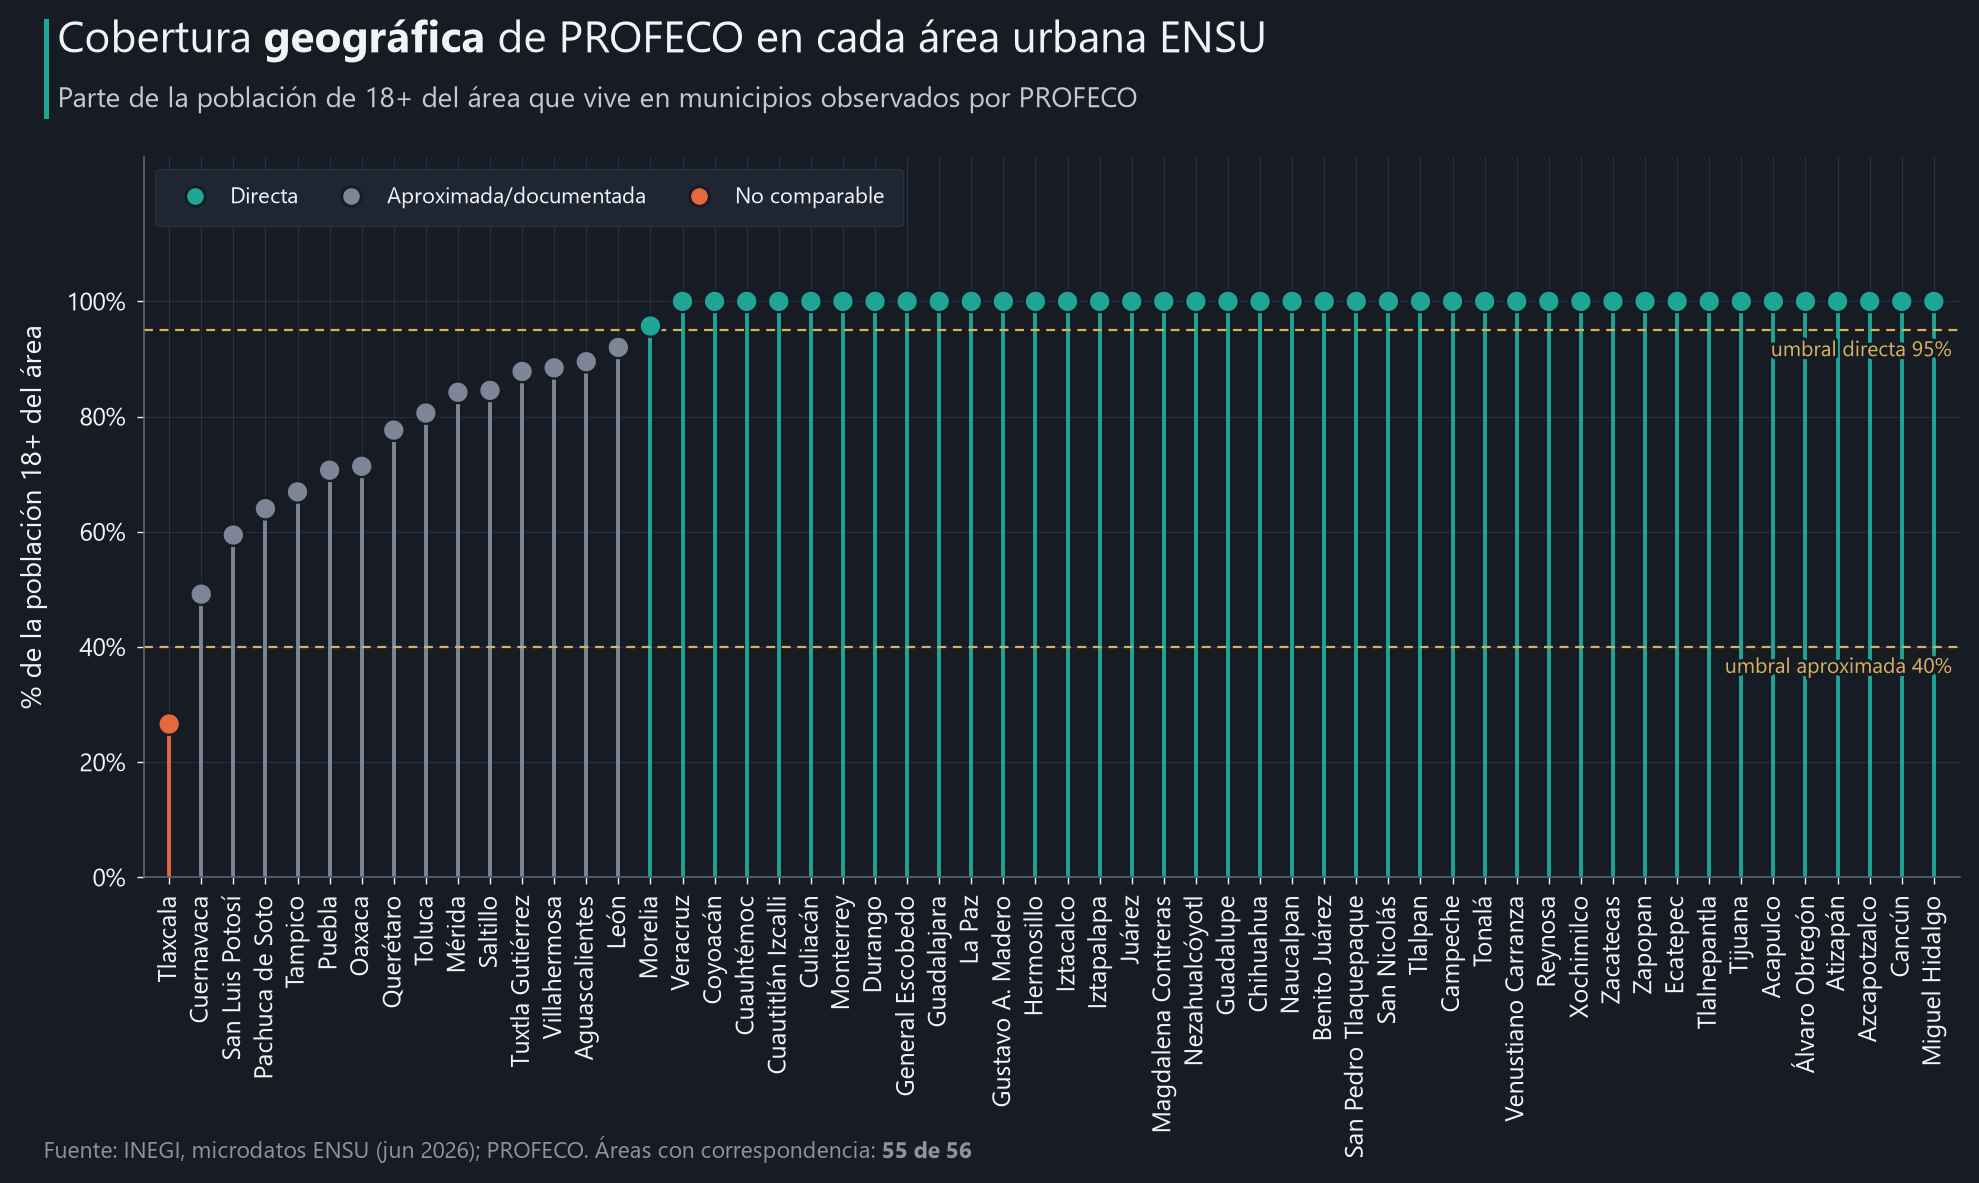

tipo_correspondencia
directa                   44
aproximada/documentada    19
no comparable              9
Name: count, dtype: int64

,estado,municipio_profeco,cve_ent,cve_mun,cd_ensu,area_urbana_ensu,correspondencia,tipo_correspondencia,incluir,participacion_municipio_area_pct,cobertura_profeco_area_pct,incluye_municipio_principal,municipios_area_ensu,registros_profeco,establecimientos_profeco
0,Guerrero,Acapulco de Juárez,12,001,21,Acapulco de Juárez,True,directa,True,100.0,100.0,True,1.0,13558,38
1,Aguascalientes,Aguascalientes,01,001,01,Aguascalientes,True,aproximada/documentada,True,89.535168,89.535168,True,2.0,15867,48
2,Estado de México,Atizapán de Zaragoza,15,013,90,Atizapán de Zaragoza,True,directa,True,100.0,100.0,True,1.0,6045,10
3,Estado de México,Atizapán,15,013,90,Atizapán de Zaragoza,True,directa,True,100.0,100.0,True,1.0,2,1
4,Ciudad de México,Azcapotzalco,09,002,71,Azcapotzalco,True,directa,True,100.0,100.0,True,1.0,10480,16
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,Estado de México,Tultitlán,15,NaN,NaN,NaN,False,no comparable,False,<NA>,NaN,False,NaN,2526,31
68,Estado de México,Cuautitlán,15,NaN,NaN,NaN,False,no comparable,False,<NA>,NaN,False,NaN,1331,4
69,Estado de México,Chicoloapan,15,NaN,NaN,NaN,False,no comparable,False,<NA>,NaN,False,NaN,3,3
70,Estado de México,Tecámac,15,NaN,NaN,NaN,False,no comparable,False,<NA>,NaN,False,NaN,3,3


In [6]:
matched = match(profeco_mun, comp)
homolog = classify(matched, comp)
cov = homolog.dropna(subset=["cd_ensu"]).drop_duplicates("cd_ensu").sort_values("cobertura_profeco_area_pct")
from src import charts
charts.coverage_strip(cov, UMBRAL_APROXIMADA, UMBRAL_DIRECTA, ROOT / "outputs/charts/00a_cobertura_geografica.png")
plt.show()
display(homolog.tipo_correspondencia.value_counts())
display(homolog.drop(columns=["observaciones"]).round(1))

In [7]:
display(homolog.loc[~homolog.incluir, ["estado", "municipio_profeco", "area_urbana_ensu",
        "cobertura_profeco_area_pct", "registros_profeco", "observaciones"]])
display(Markdown("Alias aplicados (nombre PROFECO distinto del oficial INEGI):"))
display(homolog.loc[homolog.observaciones.str.contains("oficial|coordenadas|cabecera"),
        ["estado", "municipio_profeco", "area_urbana_ensu", "observaciones"]])

,estado,municipio_profeco,area_urbana_ensu,cobertura_profeco_area_pct,registros_profeco,observaciones
63,Tlaxcala,Tlaxcala,Tlaxcala de Xicohténcatl,26.62767,11255,Área ENSU de 21 municipio(s); este municipio a...
64,Tlaxcala,Apizaco,Tlaxcala de Xicohténcatl,26.62767,3508,Área ENSU de 21 municipio(s); este municipio a...
65,Estado de México,Huixquilucan,NaN,NaN,8444,El municipio no forma parte de ningún área urb...
66,Estado de México,Coacalco,NaN,NaN,3178,El municipio no forma parte de ningún área urb...
67,Estado de México,Tultitlán,NaN,NaN,2526,El municipio no forma parte de ningún área urb...
68,Estado de México,Cuautitlán,NaN,NaN,1331,El municipio no forma parte de ningún área urb...
69,Estado de México,Chicoloapan,NaN,NaN,3,El municipio no forma parte de ningún área urb...
70,Estado de México,Tecámac,NaN,NaN,3,El municipio no forma parte de ningún área urb...
71,Quintana Roo,Solidaridad,NaN,NaN,7454,El municipio no forma parte de ningún área urb...


Alias aplicados (nombre PROFECO distinto del oficial INEGI):

,estado,municipio_profeco,area_urbana_ensu,observaciones
3,Estado de México,Atizapán,Atizapán de Zaragoza,Existe un municipio Atizapán distinto; las coo...
25,Ciudad de México,Magdalena Contreras,La Magdalena Contreras,Nombre oficial de la alcaldía incluye «La». Ár...
37,Querétaro,Santiago de Querétaro,Querétaro,PROFECO usa el nombre de la cabecera; el munic...
43,Jalisco,Tlaquepaque,San Pedro Tlaquepaque,Nombre oficial abreviado en PROFECO. Área ENSU...
47,Estado de México,Tlalnepantla,Tlalnepantla de Baz,Nombre oficial abreviado en PROFECO. Área ENSU...


In [8]:
# Controles de la homologación
assert len(homolog) == len(profeco_mun)
assert homolog.groupby("cd_ensu").area_urbana_ensu.nunique().le(1).all()
assert homolog.cobertura_profeco_area_pct.dropna().le(100.01).all()
assert not homolog.loc[homolog.incluir, "cd_ensu"].isna().any()
homolog.to_csv(PROC / "homologacion_geografica.csv", index=False, encoding="utf-8-sig")
areas.to_csv(PROC / "ensu_percepcion_areas.csv", index=False, encoding="utf-8-sig")
comp.drop(columns="mun_norm").to_csv(PROC / "ensu_composicion_areas.csv", index=False, encoding="utf-8-sig")
(ROOT / "data/metadata/ensu_manifest.json").write_text(json.dumps({
    "fuente": "INEGI, Encuesta Nacional de Seguridad Pública Urbana (ENSU)", "periodo": PERIODO,
    "levantamiento": "22 de mayo al 12 de junio de 2026 (comunicado INEGI)",
    "indicador": "Cuadro 1.7: % de población 18+ que se siente segura en su ciudad",
    "archivos_tabulados": manifest(),
    "microdatos": "https://www.inegi.org.mx/contenidos/programas/ensu/microdatos/ensu_bd_2026_csv.zip",
    "catalogo_ciudades": "https://www.inegi.org.mx/contenidos/programas/ensu/doc/ensu2025_catalogo_ciudades_interes.pdf",
}, ensure_ascii=False, indent=2), encoding="utf-8")
n_areas = homolog.loc[homolog.incluir, "cd_ensu"].nunique()
display(Markdown(
    f"**Resultado:** {homolog.incluir.sum()} de {len(homolog)} municipios PROFECO corresponden a "
    f"**{n_areas} áreas urbanas ENSU** ({(homolog.tipo_correspondencia == 'directa').sum()} directas, "
    f"{(homolog.tipo_correspondencia == 'aproximada/documentada').sum()} aproximadas). "
    f"{(~homolog.incluir).sum()} municipios quedan fuera: seis del Estado de México fuera de las áreas ENSU "
    "y Solidaridad (Q. Roo) no pertenecen a un área ENSU; Tlaxcala y Apizaco cubren solo 27 % de la suya. "
    "La correspondencia geográfica es necesaria, no suficiente: falta verificar la cobertura de la canasta."))

**Resultado:** 63 de 72 municipios PROFECO corresponden a **55 áreas urbanas ENSU** (44 directas, 19 aproximadas). 9 municipios quedan fuera: seis del Estado de México fuera de las áreas ENSU y Solidaridad (Q. Roo) no pertenecen a un área ENSU; Tlaxcala y Apizaco cubren solo 27 % de la suya. La correspondencia geográfica es necesaria, no suficiente: falta verificar la cobertura de la canasta.